# EE-411 — Fundamentals of Inference and Learning

## Homework 2 — Unsupervised learning

### Part 1 — Classification with the K-means algorithm

The K-means algorithm is a fundamental tool in unsupervised learning. Consider a problem with a dataset $\mathcal{D} = \left\{x_i\right\}_{i=1}^n$ where $x_i \in \mathbb{R}^d$ with no labels. We aim to find hidden structure within the data, namely clusters in the dataset. Classifiers have been studied in the exercise sessions, mainly for supervised learning. Here, the data are not labeled.

The K-means algorithm tries to classify the dataset into $K$ clusters. Each cluster is represented by a centroid, meaning the average of the points within the cluster. We denote by $C_k$ the set of points of a cluster $k$ and $\mu_k$ its centroid. Then, the algorithm minimizes the intra-cluster variance, in other words, it tries to reduce the distance between the points of the cluster and the centroid.

More technically, the algorithm works iteratively in two main steps:

- Points are assigned to clusters based on their proximity to existing centroids.
- Centroids are updated by taking the average of the points assigned to each cluster.

The loss function of the problem can be written as:
$$J(\mu_1, ..., \mu_K) = \sum_{i=1}^{n} \, \lVert x_i - \mu(i)\rVert^2 \; ,$$
where $\mu(i)$ is the centroid of the cluster assigned to $x_i$.

Let us examine the choice of this loss function. Does it match the aforementioned rules? Then, can it help us understand whether the algorithm converges?

Additionally, until Question 8, we assume that the clusters $C_k$ are disjoint, especially at initialization.

#### Question 1

First, let us familiarize ourselves with the loss function:

- Prove the second equality:

   $$J(\mu_1, ..., \mu_K) = \sum_{i=1}^{n} \, \lVert x_i - \mu(i)\rVert^2 = \sum_{k=1}^{K} \sum_{x_i \in C_k} \, \lVert x_i - \mu_k \rVert^2$$

- What does the term $\sum_{x_i \in C_k} \, \lVert x_i - \mu_k \rVert^2$ represent?

- Explain why this form of the loss function is more convenient.

#### Answer (1)
**1. Prove the equality :**

Since the clusters $C_1,\ldots,C_K$ form a partition of the dataset, each point $x_i$ belongs to exactly one cluster $C_k$. By definition, if $x_i\in C_k$, then $\mu(i)=\mu_k$.

Therefore, we can rewrite the sum over all data points as a sum over the clusters :

$$
\begin{aligned}
J(\mu_1,\ldots,\mu_K)
=\sum_{i=1}^{n}\left\|x_i-\mu(i)\right\|^2
=\sum_{k=1}^{K}\sum_{x_i\in C_k}\left\|x_i-\mu_k\right\|^2
\end{aligned}
$$

This proves the second equality.

**2. What does the term $\sum_{x_i \in C_k} \, \lVert x_i - \mu_k \rVert^2$ represent ?**

It represents the sum of squared Euclidean distances between the points in cluster $C_k$ and their centroid $\mu_k$. It measures the dispersion of the points within the cluster. A smaller value indicates a more compact cluster.

**3. Explain why this form of the loss function is more convenient :**

This form decomposes the total loss into a sum of individual cluster contributions. For fixed cluster assignments, each term depends only on its corresponding centroid $\mu_k$.

Therefore, the loss can be minimized independently with respect to each centroid, which simplifies the mathematical analysis and the centroid update step of the K-means algorithm.

#### Question 2

Let us focus on the first step of the algorithm. Consider a single point $x_i$ and introduce the time dependence. Also, we use a prime ($'$) to denote the variables after the new assignment of the data points.

The sequence of updates is: $(\cdot)^t \to (\cdot)^t\,{}' \to (\cdot)^{t+1} \to (\cdot)^{t+1}\,{}' \to (\cdot)^{t+2}$

Thus, at each time step $t$, the new assignments satisfy (no proof required):

$$ \mu^t(i)' = \operatorname*{arg\,min}_{\mu \in \left\{\mu^t_k\right\}_k} \lVert x_i - \mu \rVert^2$$

For instance, at time $t$ before new assignments, the vector $x_i$ belongs to a cluster $k$, while after the next assignment, it now belongs to the cluster $k'$ (it can be the same or different from the cluster $k$).

Thus, for the whole dataset, the algorithm updates the assignments as follows: $\left\{\mu^t(i) \right\} \to \left\{\mu^t(i)'\right\}$.

Compare $\lVert x_i - \mu^t(i) \rVert^2$ and $\lVert x_i - \mu^t(i)' \rVert^2$ for a given point.

#### Answer (2)

By definition, the new assignment selects the closest centroid to the point $x_i$ :

$$
\mu^t(i)'=\underset{\mu\in\{\mu_k^t\}_k}{\arg\min}\|x_i-\mu\|^2
$$

Before the reassignment, the point $x_i$ is assigned to the centroid $\mu^t(i)$.

After the reassignment, it is assigned to the closest centroid among all existing centroids. Therefore, the squared distance between $x_i$ and its newly assigned centroid cannot be greater than before.

We thus have,

$$\boxed{
\left\|x_i-\mu^t(i)'\right\|^2
\leq
\left\|x_i-\mu^t(i)\right\|^2
}
$$

The distance decreases if the point is reassigned to a strictly closer centroid, and remains unchanged otherwise.

#### Question 3

We recall that we use a prime ($'$) to denote the variables after the new assignment of the data points, so that: $\mu^t(i) \to \mu^t(i)'$ and $J_t \to J_t'$

Using the previous question, compare $J_t$ and ${J_t}'$.

Hint: Choose the appropriate expression from the two given for $J$.

#### Answer (3)

From Question 2, we know that after the reassignment, the squared distance between each point $x_i$ and its assigned centroid cannot increase :

$$
\left\|x_i-\mu^t(i)'\right\|^2
\leq
\left\|x_i-\mu^t(i)\right\|^2
$$

Since the loss function is the sum of these squared distances over all data points, we can sum this inequality over all $n$ points :

$$
\begin{aligned}
J_t'
=\sum_{i=1}^{n}\left\|x_i-\mu^t(i)'\right\|^2
\leq\sum_{i=1}^{n}\left\|x_i-\mu^t(i)\right\|^2
=J_t
\end{aligned}
$$

$$
\boxed{J_t' \leq J_t}
$$

Therefore, the total loss cannot increase during the assignment step of the K-means algorithm.

#### Question 4

Next, consider the second step of the algorithm, which minimizes the intra-cluster variance:

$$ \left\{\mu^{t+1}_k\right\}_k = \operatorname*{arg\,min}_{\left\{\mu_k\right\}_k \in \mathbb{R}^d} J'_t\left( \left\{\mu_k\right\}_k \right) = \operatorname*{arg\,min}_{\left\{\mu_k\right\}_k \in \mathbb{R}^d} \sum_{k=1}^{K} \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 $$

Show that the optimization can be done cluster-wise:

$$\mu^{t+1}_k = \operatorname*{arg\,min}_{\mu_k \in \mathbb{R}^d}  \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 $$

#### Answer (4)

The loss function after the reassignment step is

$$
J_t'(\mu_1,\ldots,\mu_K)
=
\sum_{k=1}^{K}
\underbrace{
\sum_{x_i\in C_k^{t'}}\left\|x_i-\mu_k\right\|^2
}_{J_k(\mu_k)}
$$

Since the cluster assignments are fixed, each term $J_k(\mu_k)$ depends only on its corresponding centroid $\mu_k$.

Therefore, changing one centroid only affects the loss of its own cluster, without affecting the others. Minimizing the total loss is thus equivalent to minimizing each cluster's contribution independently.

$$
\begin{aligned}
\underset{\mu_1,\ldots,\mu_K}{\arg\min}\;J_t'
&=
\underset{\mu_1,\ldots,\mu_K}{\arg\min}
\sum_{k=1}^{K}J_k(\mu_k)
\end{aligned}
$$

For each cluster $k$, we obtain

$$
\boxed{
\mu_k^{t+1}
=
\underset{\mu_k\in\mathbb{R}^d}{\arg\min}
\sum_{x_i\in C_k^{t'}}
\left\|x_i-\mu_k\right\|^2
}
$$

This shows that the optimization can be done cluster-wise.

#### Question 5

Show that the new centroids at time $t+1$ are computed according to the following equality:

$$ \mu_k^{t+1} = \frac{1}{|C^t_k{}'|}\sum_{x_i \in C^t_k{}'} x_i $$

Does this correspond to what you expected from the algorithm?

#### Answer (5)

From Question 4, we know that the new centroid of each cluster minimizes its own contribution to the loss function :

$$
J_k(\mu_k)=\sum_{x_i\in C_k^{t'}}\left\|x_i-\mu_k\right\|^2
$$

To find the minimum, we compute the gradient with respect to $\mu_k$ and set it equal to zero :

$$
\nabla_{\mu_k}J_k
=2\sum_{x_i\in C_k^{t'}}(\mu_k-x_i)=0
$$

Expanding the sum, we obtain :

$$
|C_k^{t'}|\mu_k-\sum_{x_i\in C_k^{t'}}x_i=0
$$

Therefore, assuming the cluster is non-empty :

$$
\boxed{
\mu_k^{t+1}
=\frac{1}{|C_k^{t'}|}
\sum_{x_i\in C_k^{t'}}x_i
}
$$

Since the loss is a convex quadratic function of $\mu_k$, this gives its global minimum.

This is exactly what we expected from the K-means algorithm. The new centroid is computed as the mean of all points assigned to its cluster, which minimizes the sum of squared distances within that cluster.

#### Question 6

If we focus on a cluster $k$ at time $t$ after the assignment, denoted by $C^t_k {}'$, could you compare $\sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^t \rVert^2$ and $\sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^{t+1} \rVert^2$?

What can you say about ${J_t}'$ and $J_{t+1}$? Hint: Choose the appropriate expression from the two given for $J$.

#### Answer (6)

From Question 5, we know that the new centroid $\mu_k^{t+1}$ is the mean of the points in cluster $C_k^{t'}$, which minimizes the sum of squared distances within that cluster.

Therefore, the loss of each cluster cannot increase after updating its centroid :

$$
\boxed{
\sum_{x_i\in C_k^{t'}}
\left\|x_i-\mu_k^{t+1}\right\|^2
\leq
\sum_{x_i\in C_k^{t'}}
\left\|x_i-\mu_k^t\right\|^2
}
$$

Since this inequality holds for every cluster, we can sum over all $K$ clusters :

$$
\begin{aligned}
J_{t+1}
=\sum_{k=1}^{K}\sum_{x_i\in C_k^{t'}}
\left\|x_i-\mu_k^{t+1}\right\|^2
\leq\sum_{k=1}^{K}\sum_{x_i\in C_k^{t'}}
\left\|x_i-\mu_k^t\right\|^2
=J_t'
\end{aligned}
$$

Thus, we obtain :

$$
\boxed{J_{t+1}\leq J_t'}
$$

Therefore, updating the centroids cannot increase the total loss, since each new centroid minimizes the sum of squared distances within its cluster.

#### Question 7

Combining Questions 3 and 6, compare $J_t$ and $J_{t+1}$.

#### Answer (7)

From Question 3, we know that the assignment step cannot increase the loss,

$$
J_t' \leq J_t
$$

From Question 6, we also know that updating the centroids cannot increase the loss,

$$
J_{t+1} \leq J_t'
$$

Combining these two inequalities, we obtain :

$$
J_{t+1} \leq J_t' \leq J_t
$$

Therefore,

$$
\boxed{J_{t+1} \leq J_t}
$$

This shows that the loss function is non-increasing at each iteration of the K-means algorithm.

#### Question 8

After recalling a trivial lower bound for the sequence $(J_t)_{t \geq 0}$, what can you say about the convergence?

#### Answer (8)

From Question 7, we know that the loss function is non-increasing,

$$
J_{t+1}\leq J_t
$$

Moreover, since the loss function is a sum of squared Euclidean distances, each term is non-negative. Therefore, the loss is bounded below by zero :

$$
J_t=\sum_{i=1}^{n}\left\|x_i-\mu^t(i)\right\|^2\geq 0
$$

Thus, the sequence $(J_t)_{t\geq 0}$ is non-increasing and bounded below.

By the monotone convergence theorem, it converges to a finite limit : 

$$
\boxed{\lim_{t\to\infty}J_t=J^*\geq 0}
$$

This proves the convergence of the loss values, but does not guarantee convergence to the global minimum.

#### Question 9

How sensitive is K-means to centroid initialization?

**Draw your own two-dimensional dataset** with two visually well-separated clusters, such that the algorithm with $K=2$ can converge to an undesirable clustering for some initializations.

- Draw the data points yourself.
- Mark one pair of initial centroids that leads to the expected clustering, and show the resulting clusters.
- Mark a second pair of initial centroids that leads to an undesirable clustering, and show the resulting clusters.
- Briefly explain why the initialization matters.

#### Answer (9)

Good initialization: J = 364.00
Bad initialization: J = 195.00


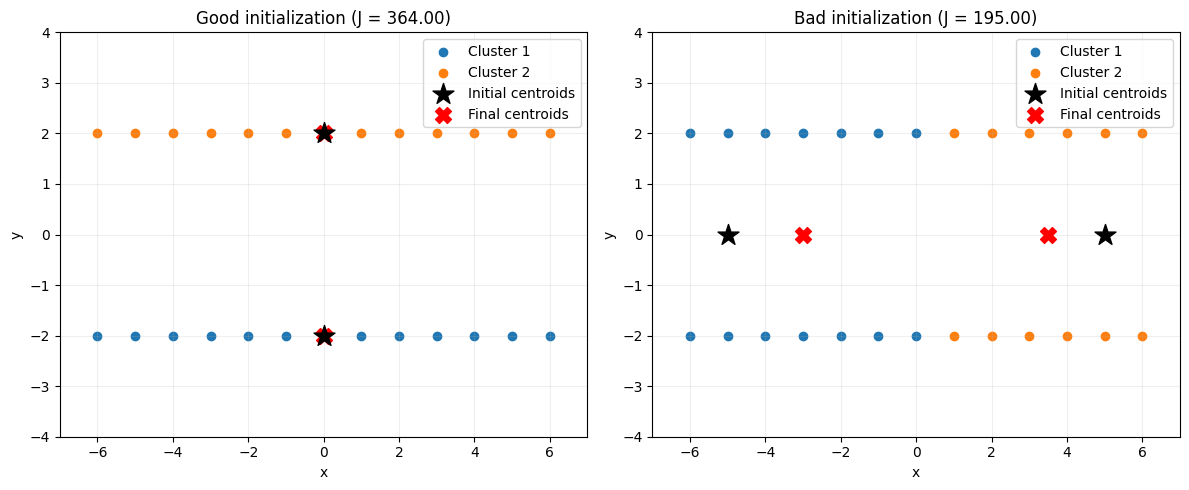

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Create two visually separated horizontal clusters
x = np.linspace(-6, 6, 13)

X = np.array([
    [xi, yi]
    for yi in [-2, 2]
    for xi in x
])

# K-means implementation
def kmeans(X, initial_centroids):
    centroids = initial_centroids.copy().astype(float)

    for _ in range(100):
        distances = np.linalg.norm(
            X[:, None, :] - centroids[None, :, :], axis=2
        )
        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([
            X[labels == k].mean(axis=0)
            for k in range(2)
        ])

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return labels, centroids

# Two different initializations
good_init = np.array([[0, -2], [0, 2]])
bad_init = np.array([[-5, 0], [5, 0]])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, init, title in zip(
    axes,
    [good_init, bad_init],
    ["Good initialization", "Bad initialization"]
):
    labels, final_centroids = kmeans(X, init)

    # Compute the final loss J
    J = np.sum((X - final_centroids[labels])**2)
    print(f"{title}: J = {J:.2f}")

    for k in range(2):
        points = X[labels == k]
        ax.scatter(points[:, 0], points[:, 1],
                   label=f"Cluster {k+1}")

    ax.scatter(init[:, 0], init[:, 1],
               marker="*", s=250, c="black",
               label="Initial centroids", zorder=5)

    ax.scatter(final_centroids[:, 0], final_centroids[:, 1],
               marker="X", s=130, c="red",
               label="Final centroids", zorder=4)

    ax.set_title(f"{title} (J = {J:.2f})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_xlim(-7, 7)
    ax.set_ylim(-4, 4)
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

The dataset consists of two visually separated horizontal groups of points.

With the good initialization, one centroid is placed in each horizontal group. K-means converges to the expected clustering, separating the upper and lower groups.

With the bad initialization, the centroids are placed on the left and right sides of the dataset. K-means converges to an undesirable clustering, separating the points vertically instead of horizontally.

This shows that K-means is sensitive to centroid initialization. Depending on the initial positions of the centroids, the algorithm can converge to different local minima, even when the dataset remains unchanged.

#### Question 10

What can you say about those configurations of centroids? What does it imply concerning the minima? Conclude your arguments by discussing the convexity of the problem.

#### Answer (10)

From Question 9, we observed that different initializations of the centroids can lead to different final clustering configurations, even when using the same dataset and $K=2$.

Both configurations are stable, but they do not have the same loss. The expected horizontal clustering has a lower loss than the undesirable vertical clustering:

$$
J_{\text{good}} < J_{\text{bad}}
$$

This shows that K-means can converge to a local minimum that is not the global minimum.

Indeed, for a convex optimization problem, every local minimum is also a global minimum. Since K-means can have local minima with different loss values, the overall optimization problem is non-convex.

However, when the cluster assignments are fixed, the loss function is convex with respect to the centroids.

Therefore, the initialization matters because K-means is not guaranteed to find the global minimum, even though its loss decreases or remains constant at each iteration.

#### Question 11

We can also quickly generalize our algorithm.

In some situations, you are aiming at favoring some directions in your data and penalizing the others, so that you can weigh the Euclidean distance according to:

$$d^{(w)}(x_{i}, \mu(i)) = \frac{\sum_{j=1}^d w_j(x_{ij} - \mu(i)_j)^2}{\sum_{j=1}^d w_j} $$

Assume $w_j > 0$ for every coordinate $j$.

Show that with a change of variables, the problem remains the same.

#### Answer (11)
We consider the weighted squared Euclidean distance:

$$
d^{(w)}(x_i,\mu(i))
=
\frac{\sum_{j=1}^{d}w_j(x_{ij}-\mu(i)_j)^2}
{\sum_{j=1}^{d}w_j}
$$

To recover the standard K-means problem, we introduce the following change of variables:

$$
\tilde{x}_{ij}
=
\sqrt{\frac{w_j}{\sum_{l=1}^{d}w_l}}\,x_{ij}
\qquad
\tilde{\mu}(i)_j
=
\sqrt{\frac{w_j}{\sum_{l=1}^{d}w_l}}\,\mu(i)_j
$$

Using these new variables, we obtain:

$$
\begin{aligned}
d^{(w)}(x_i,\mu(i))
&=
\frac{\sum_{j=1}^{d}w_j(x_{ij}-\mu(i)_j)^2}
{\sum_{j=1}^{d}w_j}\\[6pt]
&=
\sum_{j=1}^{d}
(\tilde{x}_{ij}-\tilde{\mu}(i)_j)^2\\[6pt]
&=
\left\|\tilde{x}_i-\tilde{\mu}(i)\right\|^2
\end{aligned}
$$

Therefore, the weighted loss function becomes:

$$
\boxed{
J^{(w)}
=
\sum_{i=1}^{n}
\left\|\tilde{x}_i-\tilde{\mu}(i)\right\|^2
}
$$

This is exactly the standard K-means loss function applied to the transformed data.

Since all weights are strictly positive, the transformation is invertible. Thus, the weighted K-means problem is equivalent to the standard K-means problem after rescaling the coordinates.

### Part 2 — Restricted Boltzmann machines

#### Introduction

Boltzmann machines are inspired by models from thermodynamics and statistical physics. More precisely, they are energy-based models that use the well-known Boltzmann distribution, written in physics notation as:

$$ P\left( E \right)  = \frac{1}{Z} \exp \left( -\frac{E}{k_b T} \right)$$

In the statistical inference framework, this becomes:
$$
P(\mathbf{v} \mid J, \mathbf{b}) \propto e^{\mathbf{v}^\top J\mathbf{v} + \mathbf{b}^\top\mathbf{v}} = e^{-E(\mathbf{v})}
$$
where:

- $\mathbf{v}\in\mathbb{R}^n:$ The binary vector with components $v_i = 0 \; \text{or} \; 1$

- $J \in \mathbb{R}^{n \times n}:$ The coupling matrix

- $\mathbf{b} \in  \mathbb{R}^n$: Field

- $E(\mathbf{v}) \in  \mathbb{R}$: Energy

However, one problem arose with the original Boltzmann machine (BM) — as with its parent models in statistical physics (such as the SK model) — all the units interact through complicated dependencies. For example, if we consider 3 components of $\mathbf{v}$: $v_1$, $v_2$, and $v_3$, there are trivial interactions such as the one modeled by $P(v_1, v_2)$ corresponding to the correlation between the first two components of $\mathbf{v}$, but there are also nontrivial interactions. Indeed, a term such as $P(v_1, v_2 \mid v_3)$ suggests that the correlation between $x_1$ and $v_2$ depends on $v_3$ and this is clearly nonlinear.

A really ingenious way to overcome this situation is to replace all the tricky interactions between the units $\mathbf{v}\in\mathbb{R}^n$ by connections through hidden units $\mathbf{h}\in\mathbb{R}^m$, artificially created. Indeed, correlations between two units $v_1$ and $v_2$ (especially the dependence of their correlations on other units $v_3$, $v_4$,...) can be artificially replaced by introducing a third unit $h_1$ and considering only linear correlations between $v_1 \leftrightarrow h_1$, $h_1 \leftrightarrow v_2$ and $v_1 \leftrightarrow v_2$. The units $v_i$ are now called the visible units. This model is the best-known version of BMs.

<div style="text-align: center;">
    <img src="boltzmannmachine.png" alt="Diagram here" />
</div>

However, this model is still fully connected and makes the computation really costly. Then, one can even simplify the model by considering zero interactions within each layer. This simplified model is called a restricted Boltzmann machine (RBM) (Nobel Prize in Physics 2024 🥳).

Thus, the RBM architecture consists of two layers of binary stochastic units: a **visible layer** $\mathbf{v}$ and a **hidden layer** $\mathbf{h}$. The layers are fully connected, but there are no connections within a layer, making the model a **bipartite graph**.

<div style="text-align: center;">
    <img src="rbm.png" alt="Diagram here" />
</div>

Restricted Boltzmann Machines (RBMs) are a class of energy-based probabilistic graphical models that are commonly used in machine learning for tasks such as dimensionality reduction, feature learning, and generative modeling.

#### Energy function and probabilities

The joint configuration of the visible units $\mathbf{v} \in \{0, 1\}^d$ and the hidden units $\mathbf{h} \in \{0, 1\}^m$ is associated with an **energy function**, defined as:

$$ E(\mathbf{v}, \mathbf{h}) = -\mathbf{v}^\top \mathbf{W} \mathbf{h} - \mathbf{b}^\top \mathbf{v} - \mathbf{c}^\top \mathbf{h}$$
where:

- $\mathbf{W} \in \mathbb{R}^{d \times m}$ is the weight matrix connecting the visible and hidden units,
- $\mathbf{b} \in \mathbb{R}^d$ is the field of the visible units, also called their biases,
- $\mathbf{c} \in \mathbb{R}^m$ is the field of the hidden units, also called their biases.

The energy function determines the joint probability distribution over $\mathbf{v}$ and $\mathbf{h}$:
$$ P(\mathbf{v}, \mathbf{h}) = \frac{1}{Z} \exp(-E(\mathbf{v}, \mathbf{h})) $$
where $Z$ is the **partition function**, ensuring normalization:

$$ Z = \sum_{\mathbf{v}, \mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h})) $$

The marginal probability of the visible units $\mathbf{v}$ is obtained by summing over all possible configurations of the hidden units:

$$ P(\mathbf{v}) = \frac{1}{Z} \sum_{\mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h})). $$

#### Question 12

Write a valid expression of the energy $E(\mathbf{v}, \mathbf{h})$ in the case of a BM (non-restricted) with a hidden layer.

#### Answer (12)

In a non-restricted Boltzmann Machine, connections are allowed not only between visible and hidden units, but also between units within the same layer.

Therefore, compared to the RBM, we need to add interaction terms between visible units and between hidden units.

A valid energy function is :

$$
\boxed{
E(\mathbf{v},\mathbf{h})
=
-\mathbf{v}^T W\mathbf{h}
-\frac{1}{2}\mathbf{v}^T A\mathbf{v}
-\frac{1}{2}\mathbf{h}^T B\mathbf{h}
-\mathbf{b}^T\mathbf{v}
-\mathbf{c}^T\mathbf{h}
}
$$

where $A\in\mathbb{R}^{d\times d}$ and $B\in\mathbb{R}^{m\times m}$ represent the interactions within the visible and hidden layers, respectively. We assume these matrices are symmetric with zero diagonals.

The factor $\frac{1}{2}$ avoids counting each interaction twice.

Unlike the RBM, this model includes connections within each layer, making the dependencies between units more complex.

#### Conditional independence

#### Question 13

One of the key properties of RBMs is the **conditional independence** between units within a layer:

Compute the conditional probability and show that:

$$ P(h_j = 1 \mid \mathbf{v}) = \sigma\left(c_j + \sum_{i} v_i W_{ij}\right) $$
and
$$ P(v_i = 1 \mid \mathbf{h}) = \sigma\left(b_i + \sum_{j} h_j W_{ij}\right) $$

where $\sigma(x) = \frac{1}{1 + e^{-x}}$ is the sigmoid activation function.

This bipartite structure enables efficient Gibbs sampling for approximating the intractable joint distribution $P(\mathbf{v}, \mathbf{h})$.

#### Answer (13)

**1. Conditional probability of the hidden units**

We start from the energy function of the RBM:

$$
E(\mathbf{v},\mathbf{h})
=-\mathbf{v}^TW\mathbf{h}-\mathbf{b}^T\mathbf{v}-\mathbf{c}^T\mathbf{h}
$$

Expanding and grouping the terms depending on the hidden units, we obtain:

$$
E(\mathbf{v},\mathbf{h})
=-\sum_j h_j\left(c_j+\sum_i v_iW_{ij}\right)-\sum_i b_iv_i
$$

Let $a_j=c_j+\sum_i v_iW_{ij}$.

Since the visible units are fixed, the term involving $\mathbf b$ cancels in the conditional probability:

$$
P(\mathbf{h}\mid\mathbf{v})
=
\frac{\exp\left(\sum_j h_ja_j\right)}
{\sum_{\mathbf{h}'}\exp\left(\sum_j h_j'a_j\right)}
$$

Since the hidden units are binary, the denominator factorizes:

$$
P(\mathbf{h}\mid\mathbf{v})
=
\prod_j\frac{e^{h_ja_j}}{1+e^{a_j}}
$$

This shows that the hidden units are conditionally independent given $\mathbf v$.

For $h_j=1$, we obtain:

$$
\begin{aligned}
P(h_j=1\mid\mathbf{v})
&=\frac{e^{a_j}}{1+e^{a_j}}\\
&=\frac{1}{1+e^{-a_j}}\\
&=\sigma(a_j)
\end{aligned}
$$

Therefore:

$$
\boxed{
P(h_j=1\mid\mathbf{v})
=\sigma\left(c_j+\sum_i v_iW_{ij}\right)
}
$$

**2. Conditional probability of the visible units**

Similarly, by fixing the hidden units, the energy can be rewritten as:

$$
E(\mathbf{v},\mathbf{h})
=-\sum_i v_i\left(b_i+\sum_j h_jW_{ij}\right)-\sum_j c_jh_j
$$

Let $a_i=b_i+\sum_jh_jW_{ij}$.

Using the same reasoning, the visible units are conditionally independent given $\mathbf h$, and:

$$
P(v_i=1\mid\mathbf{h})
=\frac{e^{a_i}}{1+e^{a_i}}
=\sigma(a_i)
$$

Thus:

$$
\boxed{
P(v_i=1\mid\mathbf{h})
=\sigma\left(b_i+\sum_j h_jW_{ij}\right)
}
$$

These results show that the units within each layer are conditionally independent given the other layer, which makes sampling in RBMs computationally efficient.

#### Learning in RBMs

#### Question 14

Training an RBM involves maximizing the likelihood of the data distribution. To do so, we aim to use gradient descent/ascent on the weights (and biases).

Compute the log-likelihood $\mathcal{L}(\mathbf{v})$. Recall that this is an unsupervised learning model.

#### Answer (14)

Since the RBM is an unsupervised learning model, we aim to maximize the probability of the observed visible units $\mathbf v$.

The log-likelihood is defined as:

$$
\mathcal{L}(\mathbf{v})=\log P(\mathbf{v})
$$

From the marginal probability of the visible units, we have:

$$
P(\mathbf{v})=\frac{1}{Z}\sum_{\mathbf{h}}\exp(-E(\mathbf{v},\mathbf{h}))
$$

Therefore:

$$
\mathcal{L}(\mathbf{v})
=\log\left(\sum_{\mathbf{h}}e^{-E(\mathbf{v},\mathbf{h})}\right)-\log Z
$$

Using the energy function of the RBM:

$$
-E(\mathbf{v},\mathbf{h})
=\mathbf{b}^T\mathbf{v}
+\sum_{j=1}^{m}h_j\left(c_j+\sum_{i=1}^{d}v_iW_{ij}\right)
$$

Since the hidden units are binary, the sum over all hidden configurations can be factorized:

$$
\sum_{\mathbf{h}}e^{-E(\mathbf{v},\mathbf{h})}
=
e^{\mathbf{b}^T\mathbf{v}}
\prod_{j=1}^{m}
\left(1+e^{c_j+\sum_i v_iW_{ij}}\right)
$$

Taking the logarithm, we finally obtain:

$$
\boxed{
\mathcal{L}(\mathbf{v})
=
\mathbf{b}^T\mathbf{v}
+\sum_{j=1}^{m}
\log\left(1+e^{c_j+\sum_i v_iW_{ij}}\right)
-\log Z
}
$$

This is the log-likelihood of a visible configuration $\mathbf v$. Maximizing it allows the RBM to learn the distribution of the observed data.

#### Question 15

Compute the gradient of the log-likelihood with respect to the weights $\mathbf{W}$ and the biases $\mathbf{b}$, $\mathbf{c}$:

#### Answer (15)

From Question 14, the log-likelihood is:

$$
\mathcal{L}(\mathbf{v})
=
\log\left(\sum_{\mathbf{h}}e^{-E(\mathbf{v},\mathbf{h})}\right)
-\log Z
$$

To compute its gradient, we consider a parameter $\theta$, which can be a weight or a bias.

Differentiating the first term, we obtain:

$$
\begin{aligned}
\frac{\partial}{\partial\theta}
\log\sum_{\mathbf{h}}e^{-E(\mathbf{v},\mathbf{h})}
&=
-\frac{\sum_{\mathbf{h}}e^{-E(\mathbf{v},\mathbf{h})}
\frac{\partial E}{\partial\theta}}
{\sum_{\mathbf{h}}e^{-E(\mathbf{v},\mathbf{h})}}\\
&=
-\mathbb{E}_{\mathbf{h}\mid\mathbf{v}}
\left[\frac{\partial E}{\partial\theta}\right]
\end{aligned}
$$

Similarly, differentiating the partition function gives:

$$
\frac{\partial\log Z}{\partial\theta}
=
-\mathbb{E}_{\mathbf{v}',\mathbf{h}}
\left[\frac{\partial E}{\partial\theta}\right]
$$

Combining both terms:

$$
\boxed{
\frac{\partial\mathcal{L}}{\partial\theta}
=
-\mathbb{E}_{\mathbf{h}\mid\mathbf{v}}
\left[\frac{\partial E}{\partial\theta}\right]
+
\mathbb{E}_{\mathbf{v}',\mathbf{h}}
\left[\frac{\partial E}{\partial\theta}\right]
}
$$

**1. Gradient with respect to the weights $W$**

Since

$$
\frac{\partial E}{\partial W_{ij}}=-v_ih_j
$$

we obtain:

$$
\boxed{
\frac{\partial\mathcal{L}}{\partial W_{ij}}
=
v_iP(h_j=1\mid\mathbf{v})
-
\mathbb{E}_{\mathbf{v}',\mathbf{h}}[v_i'h_j]
}
$$

**2. Gradient with respect to the visible biases $\mathbf b$**

Since

$$
\frac{\partial E}{\partial b_i}=-v_i
$$

we obtain:

$$
\boxed{
\frac{\partial\mathcal{L}}{\partial b_i}
=
v_i-\mathbb{E}_{\mathbf{v}'}[v_i']
}
$$

**3. Gradient with respect to the hidden biases $\mathbf c$**

Since

$$
\frac{\partial E}{\partial c_j}=-h_j
$$

we obtain:

$$
\boxed{
\frac{\partial\mathcal{L}}{\partial c_j}
=
P(h_j=1\mid\mathbf{v})
-
\mathbb{E}_{\mathbf{v}',\mathbf{h}}[h_j]
}
$$

These gradients consist of two terms: a positive phase based on the observed data and a negative phase based on the model distribution.

The positive phase encourages the model to represent the observed data, while the negative phase reduces the probability of configurations generated by the model.

These gradients can be used to update the weights and biases through gradient ascent.

Now, it should be possible to implement the RBM!

#### Question 16 (open question)

While it seems possible to run the RBM algorithm, note that the second term in the gradient with respect to $\mathbf{W}$ is computationally expensive due to the intractability of $Z$. The contrastive divergence approximation (CD-$k$) is often used. Research this approximation. Is it sufficient, and why? Explain in your own words and cite the papers you consulted.

#### Answer (16)

**Contrastive Divergence (CD-k)**

Training an RBM by maximizing the log-likelihood is computationally expensive because the negative phase of the gradient requires an expectation over the model distribution, which involves the intractable partition function $Z$.

To overcome this problem, Hinton (2002) proposed Contrastive Divergence (CD-k), which approximates the negative phase using a small number $k$ of Gibbs sampling steps.

The algorithm starts from a real data sample $\mathbf{v}^{(0)}$ and alternates between sampling hidden and visible units:

$$
\mathbf{v}^{(0)}
\rightarrow \mathbf{h}^{(0)}
\rightarrow \mathbf{v}^{(1)}
\rightarrow \cdots
\rightarrow \mathbf{v}^{(k)}
$$

The gradient with respect to the weights is then approximated by:

$$
\boxed{
\frac{\partial \mathcal{L}}{\partial W_{ij}}
\approx
v_i^{(0)}P(h_j=1\mid\mathbf{v}^{(0)})
-
v_i^{(k)}P(h_j=1\mid\mathbf{v}^{(k)})
}
$$

**Is CD-k sufficient?**

CD-k is often sufficient for efficient practical training, especially with small values of $k$, because it significantly reduces the computational cost.

However, it does not guarantee exact maximum-likelihood learning. Since only a few Gibbs sampling steps are performed, the generated samples may not accurately represent the model distribution. Consequently, the estimated gradient is generally biased (Carreira-Perpiñán & Hinton, 2005).

Increasing $k$ can improve the approximation if the Markov chain mixes sufficiently well, but it also increases computational cost.

An alternative is Persistent Contrastive Divergence (PCD), proposed by Tieleman (2008), which maintains persistent Markov chains between parameter updates rather than restarting them from the training data. This can provide a better approximation of the model distribution.

**Conclusion**

Contrastive Divergence offers a useful trade-off between computational efficiency and accuracy. It is often effective in practice, but it does not guarantee convergence to the maximum-likelihood solution.

**References**

1. Hinton, G. E. (2002). *Training Products of Experts by Minimizing Contrastive Divergence*. Neural Computation, 14(8), 1771–1800. https://doi.org/10.1162/089976602760128018

2. Carreira-Perpiñán, M. Á., & Hinton, G. E. (2005). *On Contrastive Divergence Learning*. AISTATS, 33–40. https://proceedings.mlr.press/r5/carreira-perpinan05a.html

3. Tieleman, T. (2008). *Training Restricted Boltzmann Machines Using Approximations to the Likelihood Gradient*. ICML, 1064–1071. https://doi.org/10.1145/1390156.1390290

#### Applications of RBMs

RBMs are widely used in tasks such as:

- **Dimensionality reduction**: Similar to PCA but capable of capturing non-linear structures,
- **Feature learning**: For pre-training deep neural networks,
- **Collaborative filtering**: Used in recommendation systems.